# 03 · Baseline forecast and backtest

*Demonstration project using public data (Olist). Not affiliated with any employer.*

**Question:** what revenue should we plan for the next 2 quarters (Sep 2018 – Feb 2019) if nothing changes?
Built by `python -m src.forecast`.

- Five simple, explainable models, all **non-seasonal**: with 20 months there is no full second year to learn
  seasonality from.
- **Backtest:** rolling origin, 4 origins (Nov 2017 – Feb 2018), each forecasting the next 6 months.
- **Selection:** lowest average WAPE across the total and the 5 markets.
- **80% range:** from the selected model's own backtest errors, symmetric around the forecast.
- **Black Friday:** a labelled judgement on Nov 2018, not a learned effect.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from src import config as cfg

P = cfg.PROCESSED_DIR
cv = pd.read_csv(P / "backtest_predictions.csv")
scores = pd.read_csv(P / "backtest_scores.csv")
fc = pd.read_csv(P / "forecast.csv")
summ = json.loads((P / "forecast_summary.json").read_text())
hist = pd.read_csv(P / "monthly_total.csv")
hist = hist[hist["in_model_window"]]
for d in (cv, fc, hist):
    d["ds"] = pd.PeriodIndex(d["month"], freq="M").to_timestamp()
BEST = summ["selected_model"]

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.labelcolor": INK2, "xtick.color": MUTED,
    "ytick.color": MUTED, "text.color": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
    "font.family": ["Segoe UI", "DejaVu Sans"],
})
IMG = cfg.IMAGES_DIR
brl_m = mtick.FuncFormatter(lambda v, _: f"R$ {v/1e6:.1f}M")
pct = mtick.PercentFormatter(1.0, decimals=0)
LABEL = {"Naive": "Naive (last month)", "WindowAverage": "3-month average", "RWD": "Random walk + drift",
         "AutoETS": "AutoETS", "AutoTheta": "AutoTheta"}

## 1. Backtest scores

WAPE = total absolute error / total actual revenue. Bias = total error / total actual: negative means the
model forecast too low.

In [2]:
w = scores.pivot(index="model", columns="unique_id", values="wape")[cfg.MARKETS + ["Total"]]
w["average"] = w.mean(axis=1)
b = scores[scores["unique_id"] == "Total"].set_index("model")["bias"]
tab = pd.concat([(w * 100).round(1), (b * 100).round(1).rename("Total bias")], axis=1).sort_values("average")
tab.index = tab.index.map(LABEL)
print("WAPE by series (%), and bias on total (%)")
tab

WAPE by series (%), and bias on total (%)


,SP,RJ,MG,South,Rest of Brazil,Total,average,Total bias
model,,,,,,,,
3-month average,19.2,8.3,8.2,15.6,10.5,11.9,12.3,-10.9
Naive (last month),16.6,13.0,14.1,15.8,14.4,11.8,14.3,-4.7
AutoTheta,11.4,38.1,34.9,16.6,22.7,18.2,23.7,17.8
AutoETS,13.8,48.1,27.1,17.7,24.8,28.4,26.6,28.3
Random walk + drift,20.8,39.2,34.4,25.0,25.0,24.0,28.1,20.9


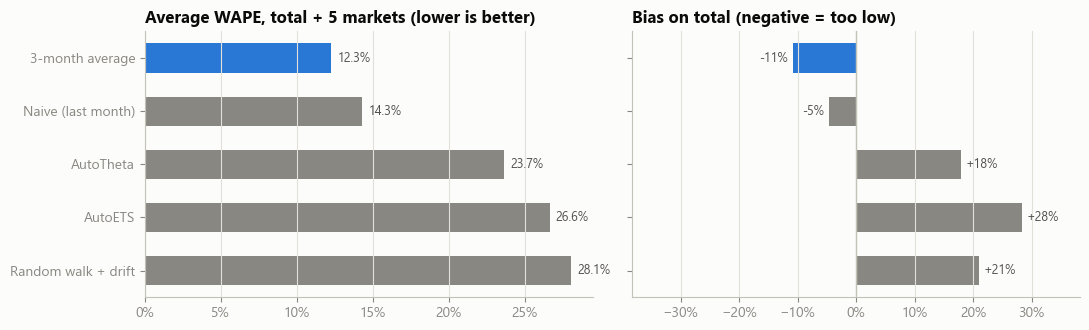

In [3]:
order = w["average"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
y = range(len(order))[::-1]
axes[0].barh(list(y), w.loc[order, "average"], height=0.55,
             color=[SERIES[0] if m == BEST else MUTED for m in order])
axes[0].set_yticks(list(y), [LABEL[m] for m in order]); axes[0].xaxis.set_major_formatter(pct)
axes[0].set_title("Average WAPE, total + 5 markets (lower is better)")
for yi, m in zip(y, order):
    axes[0].text(w.loc[m, "average"] + 0.004, yi, f"{w.loc[m, 'average']:.1%}", va="center", color=INK2, fontsize=9)
axes[1].barh(list(y), b.loc[order], height=0.55, color=[SERIES[0] if m == BEST else MUTED for m in order])
axes[1].axvline(0, color=AXIS, lw=1)
axes[1].set_yticks(list(y), [""] * len(order)); axes[1].xaxis.set_major_formatter(pct)
axes[1].set_title("Bias on total (negative = too low)")
for yi, m in zip(y, order):
    v = b.loc[m]; axes[1].text(v + (0.008 if v >= 0 else -0.008), yi, f"{v:+.0%}", va="center",
                               ha="left" if v >= 0 else "right", color=INK2, fontsize=9)
lim = max(abs(b).max() * 1.35, 0.1); axes[1].set_xlim(-lim, lim)
for ax in axes: ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
fig.tight_layout(); fig.savefig(IMG / "03_backtest_scores.png", dpi=150); plt.show()

In [4]:
t = w["Total"].sort_values()
print(f"On total revenue alone, Naive ({t['Naive']:.2%}) and the 3-month average ({t['WindowAverage']:.2%}) are "
      f"effectively tied. Across the markets the 3-month average is better in "
      f"{(w.loc['WindowAverage', cfg.MARKETS] < w.loc['Naive', cfg.MARKETS]).sum()} of 5, so it is selected.")
trend = ["RWD", "AutoETS", "AutoTheta"]
print(f"The trend models over-forecast by {b[trend].min():+.0%} to {b[trend].max():+.0%}: they carry 2017's growth "
      f"into 2018, when revenue had levelled off.")

On total revenue alone, Naive (11.75%) and the 3-month average (11.88%) are effectively tied. Across the markets the 3-month average is better in 4 of 5, so it is selected.
The trend models over-forecast by +18% to +28%: they carry 2017's growth into 2018, when revenue had levelled off.


## 2. What the backtest looked like

Each panel is one forecast origin. The 3-month average against one trend model (AutoETS) and the actuals.

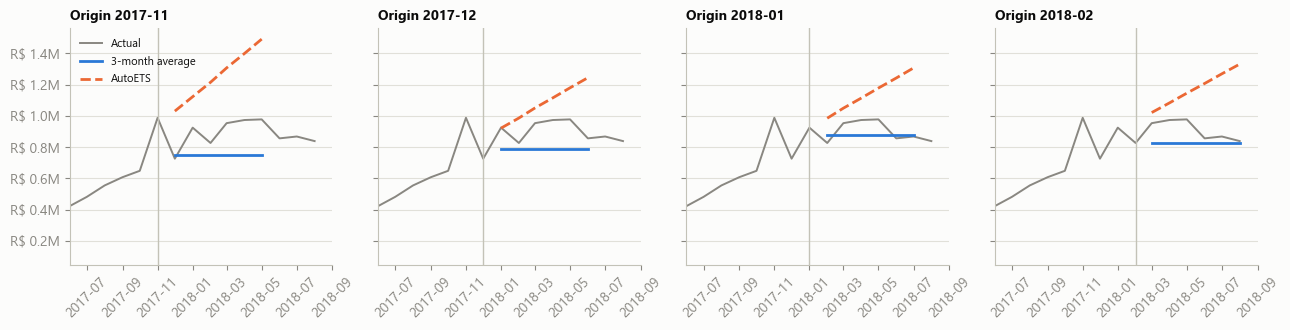

In [5]:
tot = cv[cv["unique_id"] == "Total"]
cuts = sorted(tot["cutoff"].unique())
fig, axes = plt.subplots(1, len(cuts), figsize=(13, 3.4), sharey=True)
for ax, c in zip(axes, cuts):
    g = tot[tot["cutoff"] == c]
    ax.plot(hist["ds"], hist["revenue"], color=MUTED, lw=1.4, label="Actual")
    ax.plot(g["ds"], g["WindowAverage"], color=SERIES[0], label=LABEL["WindowAverage"])
    ax.plot(g["ds"], g["AutoETS"], color=SERIES[1], ls="--", label="AutoETS")
    ax.axvline(pd.Period(c, "M").to_timestamp(), color=AXIS, lw=1)
    ax.set_title(f"Origin {c}", fontsize=10); ax.yaxis.set_major_formatter(brl_m)
    ax.set_xlim(pd.Timestamp("2017-06-01"), pd.Timestamp("2018-09-01")); ax.tick_params(axis="x", labelrotation=45)
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout(); fig.savefig(IMG / "03_backtest_paths.png", dpi=150); plt.show()

## 3. Baseline forecast, Sep 2018 – Feb 2019

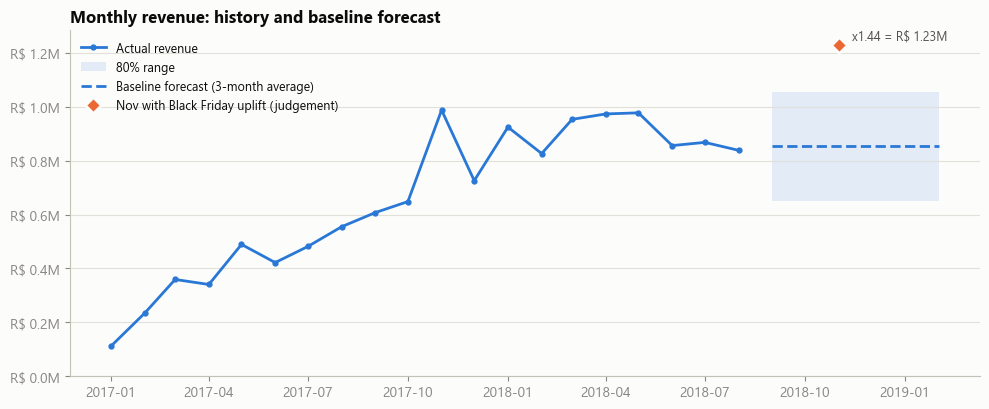

In [6]:
ft = fc[fc["unique_id"] == "Total"]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(hist["ds"], hist["revenue"], color=SERIES[0], marker="o", ms=3.5, label="Actual revenue")
ax.fill_between(ft["ds"], ft["lo80"], ft["hi80"], color=SERIES[0], alpha=0.12, lw=0, label="80% range")
ax.plot(ft["ds"], ft["forecast"], color=SERIES[0], ls="--", label=f"Baseline forecast ({LABEL[BEST]})")
nov = ft[ft["ds"].dt.month == cfg.BLACK_FRIDAY_MONTH]
ax.plot(nov["ds"], nov["forecast_bf"], marker="D", ms=8, color=SERIES[1], ls="none",
        markeredgecolor=SURF, markeredgewidth=2, label="Nov with Black Friday uplift (judgement)")
ax.annotate(f"x{summ['black_friday_uplift']:.2f} = R$ {nov['forecast_bf'].iloc[0]/1e6:.2f}M",
            (nov["ds"].iloc[0], nov["forecast_bf"].iloc[0]), xytext=(10, 4), textcoords="offset points",
            color=INK2, fontsize=9)
ax.yaxis.set_major_formatter(brl_m); ax.set_ylim(bottom=0)
ax.set_title("Monthly revenue: history and baseline forecast"); ax.legend(loc="upper left", fontsize=9)
fig.tight_layout(); fig.savefig(IMG / "03_forecast.png", dpi=150); plt.show()

In [7]:
k = fc.groupby("unique_id")[["forecast", "lo80", "hi80", "forecast_bf"]].sum().loc[cfg.MARKETS + ["Total"]]
q = fc.assign(q=fc["step"].map(lambda s: "Plan Q1 (Sep-Nov)" if s <= 3 else "Plan Q2 (Dec-Feb)")).pivot_table(
    index="unique_id", columns="q", values="forecast_bf", aggfunc="sum").loc[cfg.MARKETS + ["Total"]]
out = pd.concat([(k / 1e6).round(2), (q / 1e6).round(2).add_suffix(" incl. BF")], axis=1)
out.columns = ["6-month baseline (R$M)", "low 80%", "high 80%", "6-month incl. Black Friday"] + list(out.columns[4:])
print("Sums of monthly values. Market ranges do not add up to the total range.")
out

Sums of monthly values. Market ranges do not add up to the total range.


,6-month baseline (R$M),low 80%,high 80%,6-month incl. Black Friday,Plan Q1 (Sep-Nov) incl. BF,Plan Q2 (Dec-Feb) incl. BF
unique_id,,,,,,
SP,2.10,1.26,2.94,2.25,1.20,1.05
RJ,0.58,0.51,0.66,0.62,0.33,0.29
MG,0.59,0.51,0.66,0.63,0.34,0.29
South,0.70,0.48,0.91,0.75,0.40,0.35
Rest of Brazil,1.16,0.97,1.35,1.25,0.66,0.58
Total,5.13,3.91,6.34,5.50,2.94,2.56


## 4. What this means for the plan

In [8]:
t = fc[fc["unique_id"] == "Total"]
last6 = hist.tail(6)["revenue"].sum()
cust = pd.read_csv(P / "driver_baseline.csv").set_index("market").loc["Total", "customers_growth_vs_prior"]
print(f"- Baseline: R$ {summ['forecast_total']/1e6:.2f}M over Sep 2018 - Feb 2019 (R$ {t['forecast'].iloc[0]/1e3:.0f}k a month), "
      f"R$ {summ['forecast_total_bf']/1e6:.2f}M with the Black Friday uplift. Mar-Aug 2018 actual: R$ {last6/1e6:.2f}M.")
print(f"- 80% range on the total: R$ {t['lo80'].iloc[0]/1e3:.0f}k - {t['hi80'].iloc[0]/1e3:.0f}k a month "
      f"(+/-{t['hi80'].iloc[0]/t['forecast'].iloc[0]-1:.0%}).")
print(f"- The baseline is flat by design. In the backtest the 3-month average forecast too low by "
      f"{-b['WindowAverage']:.0%}, but those were growth months; monthly customers moved {cust:+.0%} in Jun-Aug vs Mar-May, so a flat "
      f"plan is the honest starting point. Growth has to come from explicit scenarios (Stage 4).")
print(f"- Black Friday x{summ['black_friday_uplift']:.2f} comes from a single November (2017). Treat it as a planning "
      f"assumption to confirm with the business, not a forecast.")

- Baseline: R$ 5.13M over Sep 2018 - Feb 2019 (R$ 854k a month), R$ 5.50M with the Black Friday uplift. Mar-Aug 2018 actual: R$ 5.47M.
- 80% range on the total: R$ 652k - 1056k a month (+/-24%).
- The baseline is flat by design. In the backtest the 3-month average forecast too low by 11%, but those were growth months; monthly customers moved -9% in Jun-Aug vs Mar-May, so a flat plan is the honest starting point. Growth has to come from explicit scenarios (Stage 4).
- Black Friday x1.44 comes from a single November (2017). Treat it as a planning assumption to confirm with the business, not a forecast.
